<a href="https://colab.research.google.com/github/Jess-chege/Data-Science-projects/blob/main/project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#importing the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Car price prediction using different models

In [ ]:
#importing  the dataset
data= pd.read_csv("/content/drive/MyDrive/assessment_car_price_prediction.csv")
X= data.iloc[:,:-1].values
Y = data.iloc[:,1].values
data.head(10)


,Brand,Year,Mileage,Engine_Size,Horsepower,Fuel_Type,Transmission,Previous_Owners,Accident_History,Service_Records,Price
0,BMW,2017,123015,4.2,164,Petrol,Manual,4,No,Yes,44365.58
1,Audi,2018,31641,5.0,443,Diesel,Automatic,3,Yes,Yes,55880.51
2,Ford,2013,170656,2.7,77,Hybrid,Manual,2,Yes,Yes,21485.48
3,Audi,2010,168817,2.5,429,Hybrid,Manual,3,No,No,42415.52
4,Audi,2023,159165,4.1,253,Diesel,Manual,1,Yes,Yes,56231.95
5,Honda,2010,108746,2.4,350,Diesel,Manual,5,No,No,23211.99
6,Ford,2019,187957,4.7,264,Petrol,Manual,3,No,Yes,36121.45
7,Ford,2013,41631,4.4,421,Hybrid,Manual,0,No,Yes,51118.25
8,Ford,2021,77991,2.7,264,Electric,Automatic,1,No,Yes,57545.10
9,Audi,2023,9014,4.0,224,Petrol,Automatic,5,No,Yes,59123.95


In [ ]:
data.shape

(200, 11)

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Brand             200 non-null    object 
 1   Year              200 non-null    int64  
 2   Mileage           200 non-null    int64  
 3   Engine_Size       200 non-null    float64
 4   Horsepower        200 non-null    int64  
 5   Fuel_Type         200 non-null    object 
 6   Transmission      200 non-null    object 
 7   Previous_Owners   200 non-null    int64  
 8   Accident_History  200 non-null    object 
 9   Service_Records   200 non-null    object 
 10  Price             200 non-null    float64
dtypes: float64(2), int64(4), object(5)
memory usage: 17.3+ KB


In [ ]:
data.describe()

,Year,Mileage,Engine_Size,Horsepower,Previous_Owners,Price
count,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000
mean,2015.690000,100706.900000,3.153500,245.115000,2.330000,43414.101850
std,4.208618,58297.510126,1.220465,114.774377,1.719267,11800.928061
min,2010.000000,7368.000000,1.000000,70.000000,0.000000,9863.060000
25%,2012.000000,48433.000000,2.200000,146.250000,1.000000,36086.785000
50%,2015.000000,99590.000000,3.200000,240.000000,2.000000,44086.945000
75%,2020.000000,149385.750000,4.300000,346.000000,4.000000,51117.050000
max,2023.000000,198824.000000,5.000000,446.000000,5.000000,81843.630000


In [ ]:
data.isna().sum()

,0
Brand,0
Year,0
Mileage,0
Engine_Size,0
Horsepower,0
Fuel_Type,0
Transmission,0
Previous_Owners,0
Accident_History,0
Service_Records,0


In [ ]:
print(data.dtypes)

Brand                object
Year                  int64
Mileage               int64
Engine_Size         float64
Horsepower            int64
Fuel_Type            object
Transmission         object
Previous_Owners       int64
Accident_History     object
Service_Records      object
Price               float64
dtype: object


In [ ]:
# Identifying feature types
categorical_features = data.select_dtypes(include=["object"]).columns.tolist()
numerical_features = data.select_dtypes(include=["int64", "float64"]).columns.tolist()

print("Categorical Features:", categorical_features)
print("Numerical Features:", numerical_features)

Categorical Features: ['Brand', 'Fuel_Type', 'Transmission', 'Accident_History', 'Service_Records']
Numerical Features: ['Year', 'Mileage', 'Engine_Size', 'Horsepower', 'Previous_Owners', 'Price']


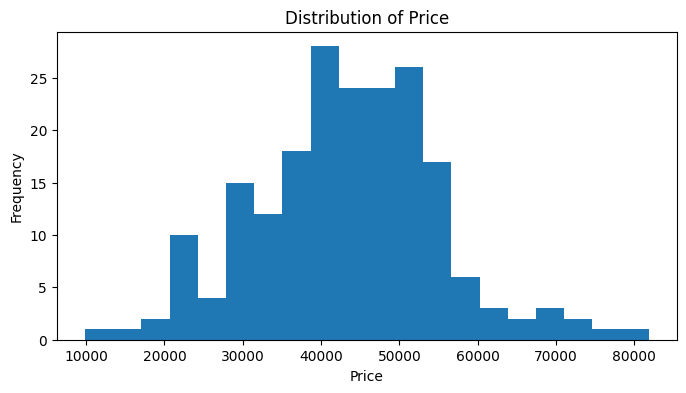

In [ ]:
#Distribution of Price
plt.figure(figsize=(8,4))
plt.hist(data["Price"], bins=20)
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.title("Distribution of Price")
plt.show()

/tmp/ipython-input-3326902727.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(price_by_brand, labels=brands)


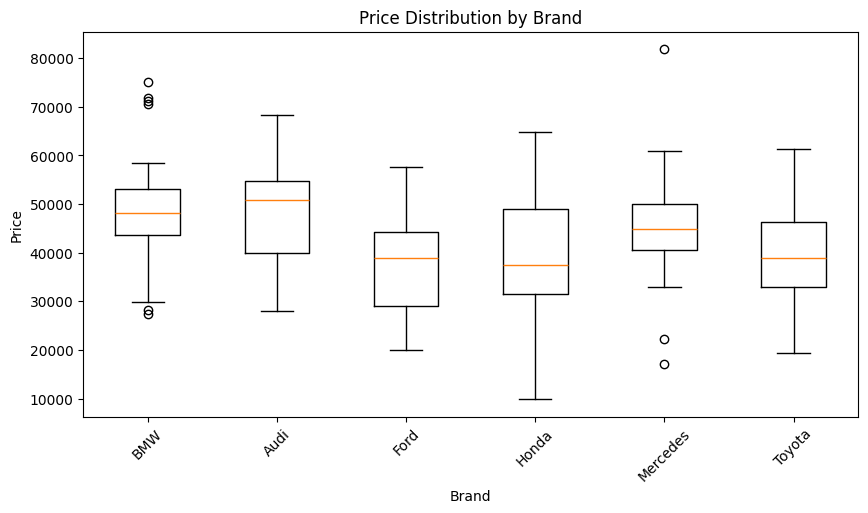

In [ ]:
#using box plotting to visualize the price
brands = data["Brand"].unique()
price_by_brand = [data[data["Brand"] == brand]["Price"] for brand in brands]

plt.figure(figsize=(10,5))
plt.boxplot(price_by_brand, labels=brands)
plt.xlabel("Brand")
plt.ylabel("Price")
plt.title("Price Distribution by Brand")
plt.xticks(rotation=45)
plt.show()

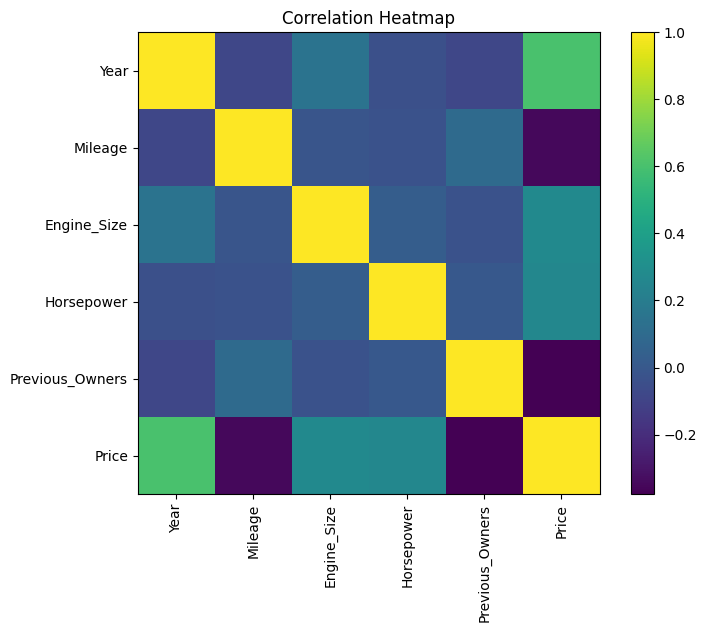

In [ ]:
#correlation heatmap
numerical_data = data.select_dtypes(include=["int64", "float64"])
corr_matrix = numerical_data.corr()

plt.figure(figsize=(8,6))
plt.imshow(corr_matrix)
plt.colorbar()
plt.xticks(range(len(corr_matrix.columns)), corr_matrix.columns, rotation=90)
plt.yticks(range(len(corr_matrix.columns)), corr_matrix.columns)
plt.title("Correlation Heatmap")
plt.show()

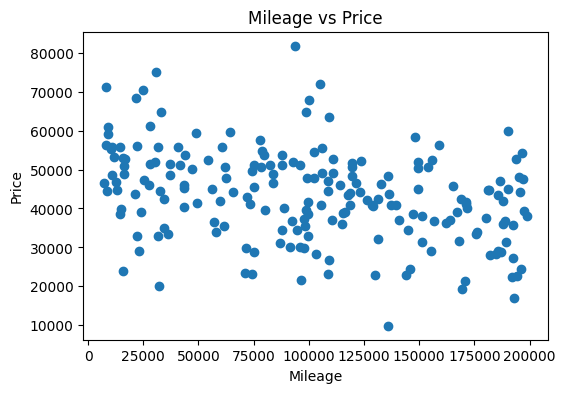

In [ ]:
plt.figure(figsize=(6,4))
plt.scatter(data["Mileage"], data["Price"])
plt.xlabel("Mileage")
plt.ylabel("Price")
plt.title("Mileage vs Price")
plt.show()

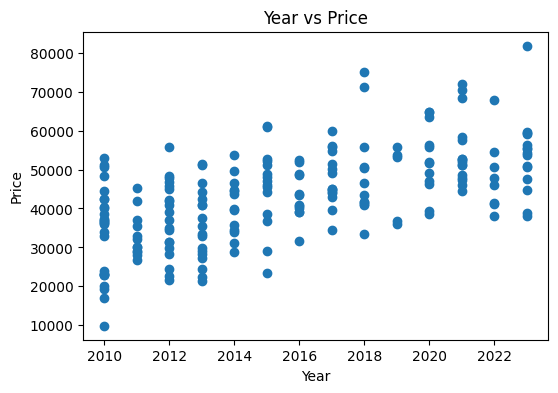

In [ ]:
plt.figure(figsize=(6,4))
plt.scatter(data["Year"], data["Price"])
plt.xlabel("Year")
plt.ylabel("Price")
plt.title("Year vs Price")
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, StandardScaler

# Copying the dataset
df = data.copy()

# Label Encoding for binary categorical variables
le = LabelEncoder()
df["Accident_History"] = le.fit_transform(df["Accident_History"])  # Yes=1, No=0
df["Service_Records"] = le.fit_transform(df["Service_Records"])      # Yes=1, No=0

# OneHotEncoding for multi-category features
# Use sparse_output=False instead of sparse
ohe = OneHotEncoder(drop='first', sparse_output=False)

# Brand
brand_encoded = ohe.fit_transform(df[["Brand"]])
brand_cols = ohe.get_feature_names_out(["Brand"])
brand_df = pd.DataFrame(brand_encoded, columns=brand_cols, index=df.index)

# Fuel_Type
fuel_encoded = ohe.fit_transform(df[["Fuel_Type"]])
fuel_cols = ohe.get_feature_names_out(["Fuel_Type"])
fuel_df = pd.DataFrame(fuel_encoded, columns=fuel_cols, index=df.index)

# Transmission
trans_encoded = ohe.fit_transform(df[["Transmission"]])
trans_cols = ohe.get_feature_names_out(["Transmission"])
trans_df = pd.DataFrame(trans_encoded, columns=trans_cols, index=df.index)

#  Drop original categorical columns
df = df.drop(columns=["Brand", "Fuel_Type", "Transmission"])

# Concatenate encoded columns
df = pd.concat([df, brand_df, fuel_df, trans_df], axis=1)

# Separate features and target
X = df.drop("Price", axis=1)
y = df["Price"]

# Train-Test Split (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

#Feature Scaling
num_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
scaler = StandardScaler()

X_train[num_features] = scaler.fit_transform(X_train[num_features])
X_test[num_features] = scaler.transform(X_test[num_features])

# Validation
print("Shapes:")
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

print("\nMissing values in X_train:", X_train.isnull().sum().sum())
print("Missing values in X_test :", X_test.isnull().sum().sum())

# First 5 rows of preprocessed training data
X_train.head()


Shapes:
X_train: (140, 16)
X_test : (60, 16)
y_train: (140,)
y_test : (60,)

Missing values in X_train: 0
Missing values in X_test : 0


,Year,Mileage,Engine_Size,Horsepower,Previous_Owners,Accident_History,Service_Records,Brand_BMW,Brand_Ford,Brand_Honda,Brand_Mercedes,Brand_Toyota,Fuel_Type_Electric,Fuel_Type_Hybrid,Fuel_Type_Petrol,Transmission_Manual
169,1.281552,0.824185,0.726283,-1.150216,-0.706762,-0.665807,0.577350,2.093947,-0.454859,-0.396264,-0.420084,-0.477567,-0.566352,1.914854,-0.577350,0.917663
97,1.042010,0.335687,-1.650201,0.535490,-0.128127,-0.665807,-1.732051,-0.477567,-0.454859,-0.396264,-0.420084,-0.477567,-0.566352,-0.522233,-0.577350,-1.089725
31,-0.395245,-1.574707,0.896031,1.151770,-0.706762,-0.665807,0.577350,-0.477567,-0.454859,2.523573,-0.420084,-0.477567,-0.566352,-0.522233,1.732051,-1.089725
12,-0.874330,-1.005761,1.235529,-1.023335,-1.285398,-0.665807,0.577350,-0.477567,-0.454859,-0.396264,2.380476,-0.477567,1.765686,-0.522233,-0.577350,-1.089725
35,0.083840,-0.117746,-1.650201,-1.150216,-0.706762,-0.665807,0.577350,-0.477567,-0.454859,-0.396264,2.380476,-0.477567,-0.566352,-0.522233,-0.577350,-1.089725


In [ ]:
# Separating features and target
X = df.drop("Price", axis=1)
y = df["Price"]

# Train-test split 70% train, 30% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Initializing the model
lin_reg = LinearRegression()

# Training the model on training data
lin_reg.fit(X_train, y_train)

LinearRegression()

In [ ]:
# Identifying numerical features for scaling (excluding target)
num_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()

# Initialize StandardScaler
scaler = StandardScaler()

# Fit on training data, transform both train & test
X_train[num_features] = scaler.fit_transform(X_train[num_features])
X_test[num_features] = scaler.transform(X_test[num_features])

In [ ]:
# Shapes
print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape :", y_test.shape)

# Check for missing values
print("\nMissing values in X_train:\n", X_train.isnull().sum().sum())
print("Missing values in X_test:\n", X_test.isnull().sum().sum())

# First 5 rows of preprocessed training data
X_train.head()


X_train shape: (140, 16)
X_test shape : (60, 16)
y_train shape: (140,)
y_test shape : (60,)

Missing values in X_train:
 0
Missing values in X_test:
 0


,Year,Mileage,Engine_Size,Horsepower,Previous_Owners,Accident_History,Service_Records,Brand_BMW,Brand_Ford,Brand_Honda,Brand_Mercedes,Brand_Toyota,Fuel_Type_Electric,Fuel_Type_Hybrid,Fuel_Type_Petrol,Transmission_Manual
169,1.281552,0.824185,0.726283,-1.150216,-0.706762,-0.665807,0.577350,2.093947,-0.454859,-0.396264,-0.420084,-0.477567,-0.566352,1.914854,-0.577350,0.917663
97,1.042010,0.335687,-1.650201,0.535490,-0.128127,-0.665807,-1.732051,-0.477567,-0.454859,-0.396264,-0.420084,-0.477567,-0.566352,-0.522233,-0.577350,-1.089725
31,-0.395245,-1.574707,0.896031,1.151770,-0.706762,-0.665807,0.577350,-0.477567,-0.454859,2.523573,-0.420084,-0.477567,-0.566352,-0.522233,1.732051,-1.089725
12,-0.874330,-1.005761,1.235529,-1.023335,-1.285398,-0.665807,0.577350,-0.477567,-0.454859,-0.396264,2.380476,-0.477567,1.765686,-0.522233,-0.577350,-1.089725
35,0.083840,-0.117746,-1.650201,-1.150216,-0.706762,-0.665807,0.577350,-0.477567,-0.454859,-0.396264,2.380476,-0.477567,-0.566352,-0.522233,-0.577350,-1.089725


In [ ]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

# Store results
poly_results = {}

# Test degrees 2 and 3
for degree in [2, 3]:
    print(f"\nPolynomial Regression (degree={degree})")

    # Transforming features
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    X_train_poly = poly.fit_transform(X_train)
    X_test_poly  = poly.transform(X_test)

    # Train Linear Regression on polynomial features
    poly_model = LinearRegression()
    poly_model.fit(X_train_poly, y_train)

    # Predictions
    y_train_pred = poly_model.predict(X_train_poly)
    y_test_pred  = poly_model.predict(X_test_poly)

    # Metrics
    r2_train = r2_score(y_train, y_train_pred)
    r2_test  = r2_score(y_test, y_test_pred)
    mae_test  = mean_absolute_error(y_test, y_test_pred)
    rmse_test = np.sqrt(mean_squared_error(y_test, y_test_pred))

    print(f"Train R²: {r2_train:.4f}")
    print(f"Test R² : {r2_test:.4f}")
    print(f"Test MAE: {mae_test:.4f}")
    print(f"Test RMSE: {rmse_test:.4f}")

    # Store results
    poly_results[degree] = {
        "model": poly_model,
        "poly_features": poly,
        "r2_train": r2_train,
        "r2_test": r2_test,
        "mae": mae_test,
        "rmse": rmse_test
    }

# Select best degree based on test R² and overfitting check
best_degree = max(poly_results, key=lambda d: poly_results[d]["r2_test"])
print(f"\nBest Polynomial Degree (based on Test R² and minimal overfitting): {best_degree}")



Polynomial Regression (degree=2)
Train R²: 0.9957
Test R² : 0.4080
Test MAE: 6851.1562
Test RMSE: 8973.4893

Polynomial Regression (degree=3)
Train R²: 1.0000
Test R² : 0.8286
Test MAE: 3800.8264
Test RMSE: 4828.3150

Best Polynomial Degree (based on Test R² and minimal overfitting): 3


In [ ]:
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Only numerical features were scaled; all others are one-hot encoded (0/1), so safe to use directly.

# Store results for comparison
svr_results = {}

# SVR configurations
svr_configs = [
    {"kernel": "rbf", "C": 100, "gamma": "auto"},
    {"kernel": "rbf", "C": 1000, "gamma": "scale"}
]

# Train, Predict, and Evaluate
for i, params in enumerate(svr_configs, 1):
    print(f"\nSVR Configuration {i}: {params}")

    # Build SVR model
    svr_model = SVR(kernel=params["kernel"], C=params["C"], gamma=params["gamma"])
    svr_model.fit(X_train, y_train)

    # Predictions
    y_train_pred = svr_model.predict(X_train)
    y_test_pred  = svr_model.predict(X_test)

    # Metrics
    r2_train = r2_score(y_train, y_train_pred)
    r2_test  = r2_score(y_test, y_test_pred)
    mae_test  = mean_absolute_error(y_test, y_test_pred)
    rmse_test = np.sqrt(mean_squared_error(y_test, y_test_pred))

    print(f"Train R²: {r2_train:.4f}")
    print(f"Test R² : {r2_test:.4f}")
    print(f"Test MAE: {mae_test:.4f}")
    print(f"Test RMSE: {rmse_test:.4f}")

    # Storing results
    svr_results[i] = {
        "model": svr_model,
        "params": params,
        "r2_train": r2_train,
        "r2_test": r2_test,
        "mae": mae_test,
        "rmse": rmse_test
    }

# Select best SVR based on test R²
best_svr_idx = max(svr_results, key=lambda k: svr_results[k]["r2_test"])
best_svr_model = svr_results[best_svr_idx]["model"]
print(f"\nBest SVR configuration: {svr_results[best_svr_idx]['params']}")



SVR Configuration 1: {'kernel': 'rbf', 'C': 100, 'gamma': 'auto'}
Train R²: 0.0441
Test R² : 0.0356
Test MAE: 9455.2015
Test RMSE: 11453.5494

SVR Configuration 2: {'kernel': 'rbf', 'C': 1000, 'gamma': 'scale'}
Train R²: 0.4032
Test R² : 0.3241
Test MAE: 7833.8363
Test RMSE: 9588.9145

Best SVR configuration: {'kernel': 'rbf', 'C': 1000, 'gamma': 'scale'}


In [ ]:
from sklearn.tree import DecisionTreeRegressor

# Store results
dt_results = {}

# Hyperparameter grids
max_depths = [3, 5, 10, None]
min_samples_splits = [2, 5, 10]
min_samples_leafs = [1, 2, 5]

# Training, evaluate, and tune Decision Tree
config_id = 0
for depth in max_depths:
    for split in min_samples_splits:
        for leaf in min_samples_leafs:
            config_id += 1
            params = {"max_depth": depth, "min_samples_split": split, "min_samples_leaf": leaf}
            dt_model = DecisionTreeRegressor(
                max_depth=depth,
                min_samples_split=split,
                min_samples_leaf=leaf,
                random_state=42
            )
            # Train
            dt_model.fit(X_train, y_train)

            # Predictions
            y_train_pred = dt_model.predict(X_train)
            y_test_pred  = dt_model.predict(X_test)

            # Metrics
            r2_train = r2_score(y_train, y_train_pred)
            r2_test  = r2_score(y_test, y_test_pred)
            mae_test  = mean_absolute_error(y_test, y_test_pred)
            rmse_test = np.sqrt(mean_squared_error(y_test, y_test_pred))

            # Store results
            dt_results[config_id] = {
                "model": dt_model,
                "params": params,
                "r2_train": r2_train,
                "r2_test": r2_test,
                "mae": mae_test,
                "rmse": rmse_test
            }

            print(f"Config {config_id}: {params}")
            print(f" Train R²: {r2_train:.4f}, Test R²: {r2_test:.4f}, MAE: {mae_test:.4f}, RMSE: {rmse_test:.4f}\n")

# Selecting best Decision Tree based on Test R² (balance overfitting)
best_dt_id = max(dt_results, key=lambda k: dt_results[k]["r2_test"])
best_dt_model = dt_results[best_dt_id]["model"]
best_params = dt_results[best_dt_id]["params"]

print(f"\nBest Decision Tree Configuration: {best_params}")
print(f"Test R²: {dt_results[best_dt_id]['r2_test']:.4f}, Train R²: {dt_results[best_dt_id]['r2_train']:.4f}")

# Feature Importance
importances = best_dt_model.feature_importances_
feature_names = X_train.columns

# Creating the new DataFrame
feat_imp_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

# Display
print("\nFeature Importances:")
print(feat_imp_df)



Config 1: {'max_depth': 3, 'min_samples_split': 2, 'min_samples_leaf': 1}
 Train R²: 0.6071, Test R²: 0.4466, MAE: 6969.8443, RMSE: 8676.2517

Config 2: {'max_depth': 3, 'min_samples_split': 2, 'min_samples_leaf': 2}
 Train R²: 0.6071, Test R²: 0.4466, MAE: 6969.8443, RMSE: 8676.2517

Config 3: {'max_depth': 3, 'min_samples_split': 2, 'min_samples_leaf': 5}
 Train R²: 0.6071, Test R²: 0.4466, MAE: 6969.8443, RMSE: 8676.2517

Config 4: {'max_depth': 3, 'min_samples_split': 5, 'min_samples_leaf': 1}
 Train R²: 0.6071, Test R²: 0.4466, MAE: 6969.8443, RMSE: 8676.2517

Config 5: {'max_depth': 3, 'min_samples_split': 5, 'min_samples_leaf': 2}
 Train R²: 0.6071, Test R²: 0.4466, MAE: 6969.8443, RMSE: 8676.2517

Config 6: {'max_depth': 3, 'min_samples_split': 5, 'min_samples_leaf': 5}
 Train R²: 0.6071, Test R²: 0.4466, MAE: 6969.8443, RMSE: 8676.2517

Config 7: {'max_depth': 3, 'min_samples_split': 10, 'min_samples_leaf': 1}
 Train R²: 0.6071, Test R²: 0.4466, MAE: 6969.8443, RMSE: 8676.2517

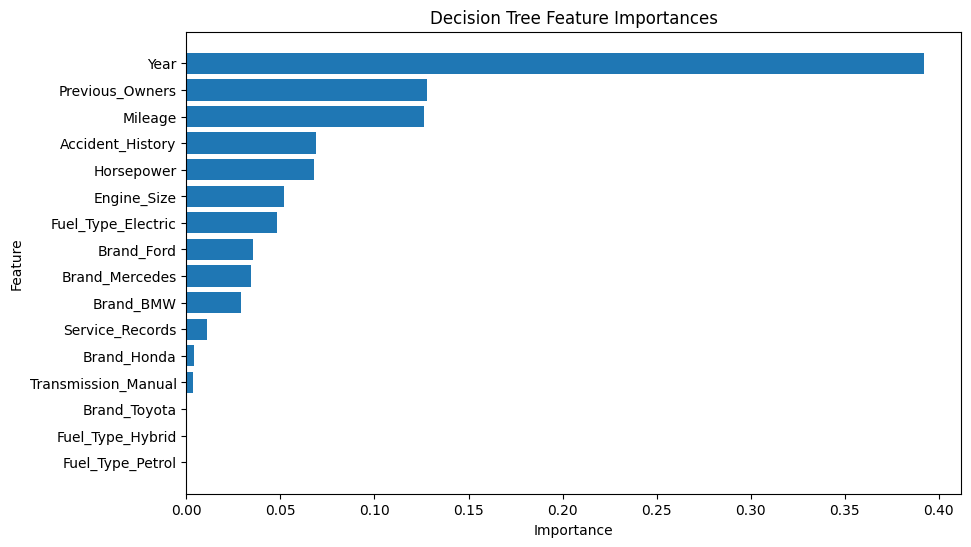

In [ ]:
#visualising
# Bar Plot of Feature Importances
plt.figure(figsize=(10,6))
plt.barh(feat_imp_df["Feature"], feat_imp_df["Importance"])
plt.gca().invert_yaxis()  # highest important feature at the top
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Decision Tree Feature Importances")
plt.show()


In [ ]:
#Creating comparison table with all models:
import time
import time
results = []

# my function to simplify the process
def evaluate(model, X_train, X_test, y_train, y_test, name):
    start = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - start

    y_train_pred = model.predict(X_train)
    y_test_pred  = model.predict(X_test)

    results.append({
        "Model": name,
        "Train R²": r2_score(y_train, y_train_pred),
        "Test R²": r2_score(y_test, y_test_pred),
        "MAE": mean_absolute_error(y_test, y_test_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_test_pred)),
        "Training Time (s)": train_time
    })

# Linear Regression
evaluate(lin_reg, X_train, X_test, y_train, y_test,
         "Multiple Linear Regression")

#Polynomial Regression (best degree)
evaluate(
    poly_results[best_degree]["model"],
    poly_results[best_degree]["poly_features"].transform(X_train),
    poly_results[best_degree]["poly_features"].transform(X_test),
    y_train, y_test,
    f"Polynomial Regression (degree {best_degree})"
)

# SVR (best)
evaluate(best_svr_model, X_train, X_test, y_train, y_test,
         "SVR (Best Params)")

# Decision Tree (best)
evaluate(best_dt_model, X_train, X_test, y_train, y_test,
         "Decision Tree (Best Params)")

# the Comparison Table
comparison_df = pd.DataFrame(results)
comparison_df


,Model,Train R²,Test R²,MAE,RMSE,Training Time (s)
0,Multiple Linear Regression,0.942828,0.934774,2349.033898,2978.686479,0.004262
1,Polynomial Regression (degree 3),1.000000,0.828619,3800.826365,4828.314998,0.028410
2,SVR (Best Params),0.403228,0.324058,7833.836287,9588.914488,0.006736
3,Decision Tree (Best Params),0.948785,0.499313,6759.085667,8252.741465,0.005534


In [ ]:
#creating predictions for Linear regression
y_pred_lin = lin_reg.predict(X_test)

In [ ]:
#creating predictions for polynomial
y_pred_poly = poly_results[best_degree]["model"].predict(
    poly_results[best_degree]["poly_features"].transform(X_test)
)

In [ ]:
#creating predictions for the svr model
y_pred_svr = best_svr_model.predict(X_test)

In [ ]:
#creating predictions for the decision tree regression
y_pred_dt = best_dt_model.predict(X_test)

In [ ]:
#Scatter plot: Predicted vs Actual prices (test set)
#Add diagonal line representing perfect predictions
#Color points by prediction error magnitude
#Add R² score to plot title



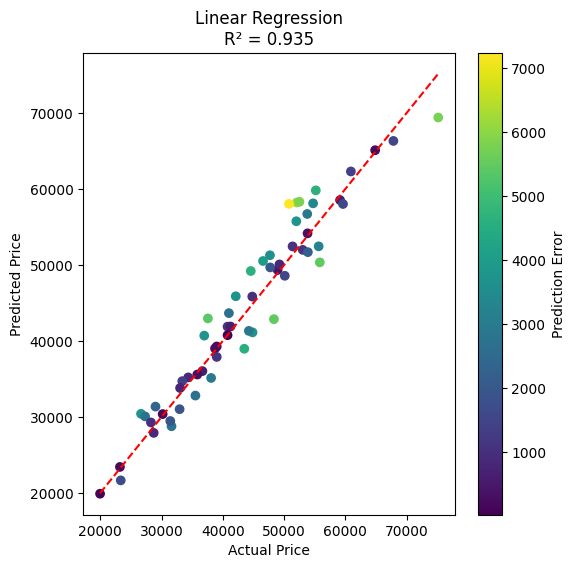

In [ ]:
#Multiple Linear Regression – Predicted vs Actual (Test Set)
# Calculating the absolute prediction errors
errors = np.abs(y_test - y_pred_lin)

# Calculating the R² score
r2 = r2_score(y_test, y_pred_lin)

# Create scatter plot: Actual vs Predicted
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_lin, c=errors)

# Diagonal line representing perfect predictions
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

# Axis labels and title
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title(f"Linear Regression\nR² = {r2:.3f}")

# Color bar to show magnitude of prediction error
plt.colorbar(label="Prediction Error")

plt.show()

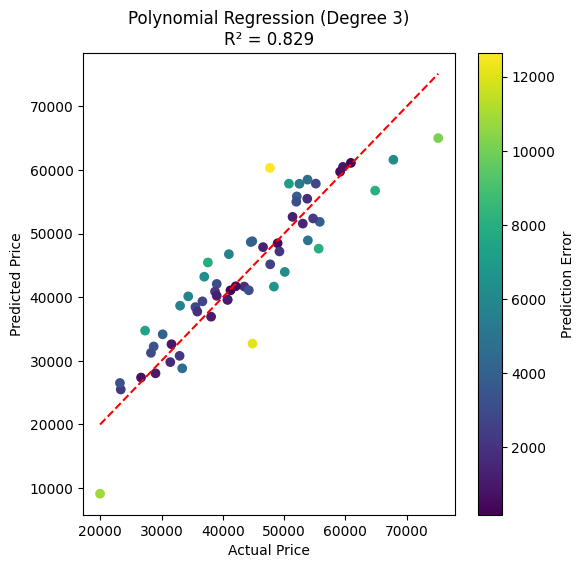

In [ ]:
#visualizing for the Polynomial Regression – Predicted vs Actual
# Calculating absolute prediction errors
errors = np.abs(y_test - y_pred_poly)

# Calculating R² score
r2 = r2_score(y_test, y_pred_poly)

# Scatter plot
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_poly, c=errors)

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

# Labels and title
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title(f"Polynomial Regression (Degree {best_degree})\nR² = {r2:.3f}")

# Error color scale
plt.colorbar(label="Prediction Error")

plt.show()


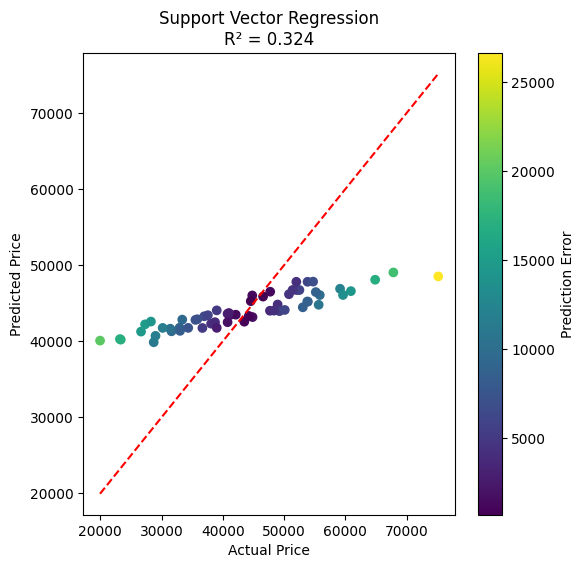

In [ ]:
#Support Vector Regression – Predicted vs Actual
# Calculating prediction errors
errors = np.abs(y_test - y_pred_svr)

# R² score
r2 = r2_score(y_test, y_pred_svr)

# Scatter plot of actual vs predicted values
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_svr, c=errors)

# Ideal prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

# Plot labels
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title(f"Support Vector Regression\nR² = {r2:.3f}")

# Error magnitude legend
plt.colorbar(label="Prediction Error")

plt.show()


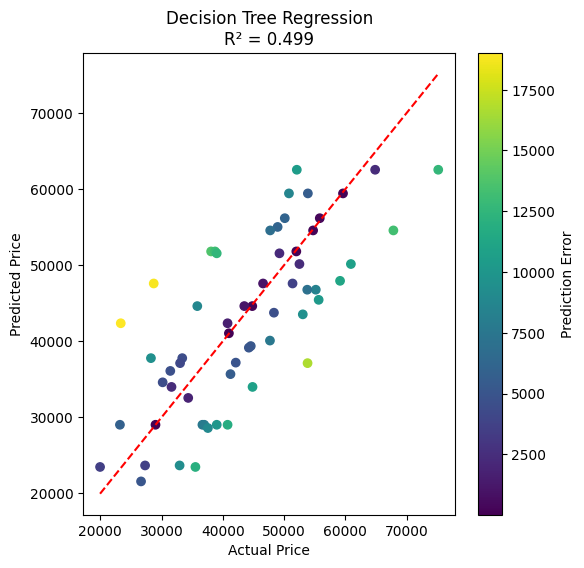

In [ ]:
#Decision Tree Regression – Predicted vs Actual
# Calculating absolute prediction errors
errors = np.abs(y_test - y_pred_dt)

# Compute R² score
r2 = r2_score(y_test, y_pred_dt)

# Create scatter plot
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_dt, c=errors)

# Diagonal line for perfect predictions
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

# Axis labels and title
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title(f"Decision Tree Regression\nR² = {r2:.3f}")

# Color bar for error magnitude
plt.colorbar(label="Prediction Error")

plt.show()


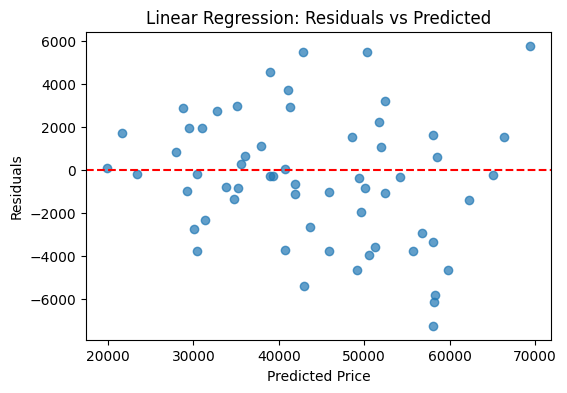

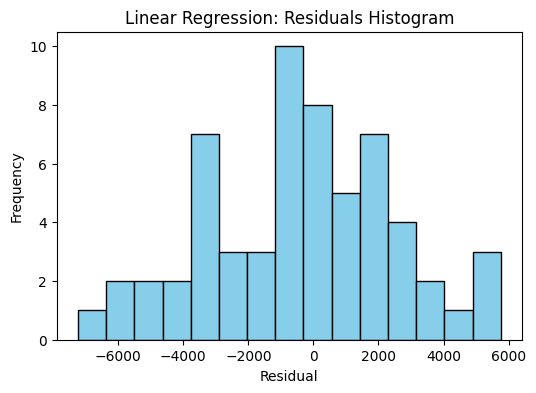

In [ ]:
#Residual Analysis
#For each model:

#Calculate residuals (actual - predicted)
#Create residual plot (residuals vs predicted values)
#Plot histogram of residuals
#Analyze residual patterns:
#Are residuals randomly distributed?
##Is there any pattern indicating model limitations?
#Are there outliers?
# Calculating residuals
residuals_lin = y_test - y_pred_lin

# Residuals vs Predicted
plt.figure(figsize=(6,4))
plt.scatter(y_pred_lin, residuals_lin, alpha=0.7)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("Linear Regression: Residuals vs Predicted")
plt.show()

# Histogram of residuals
plt.figure(figsize=(6,4))
plt.hist(residuals_lin, bins=15, color='skyblue', edgecolor='black')
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Linear Regression: Residuals Histogram")
plt.show()


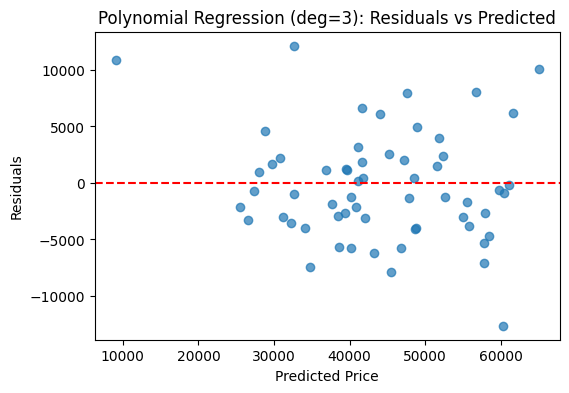

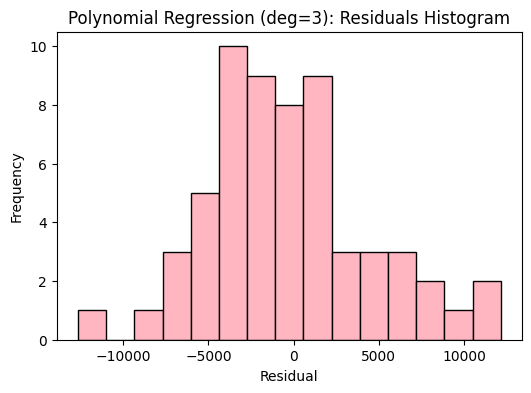

In [ ]:
#Polynomial Regression
residuals_poly = y_test - y_pred_poly

plt.figure(figsize=(6,4))
plt.scatter(y_pred_poly, residuals_poly, alpha=0.7)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title(f"Polynomial Regression (deg={best_degree}): Residuals vs Predicted")
plt.show()

plt.figure(figsize=(6,4))
plt.hist(residuals_poly, bins=15, color='lightpink', edgecolor='black')
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title(f"Polynomial Regression (deg={best_degree}): Residuals Histogram")
plt.show()


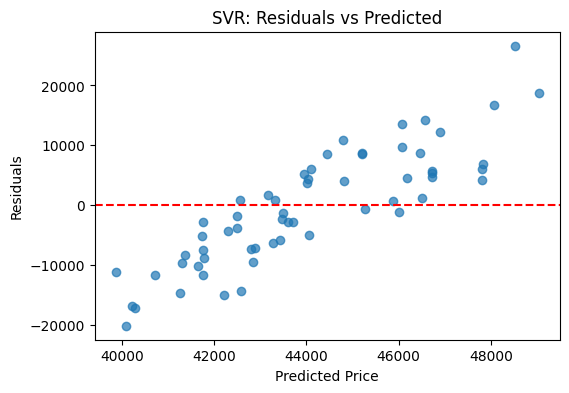

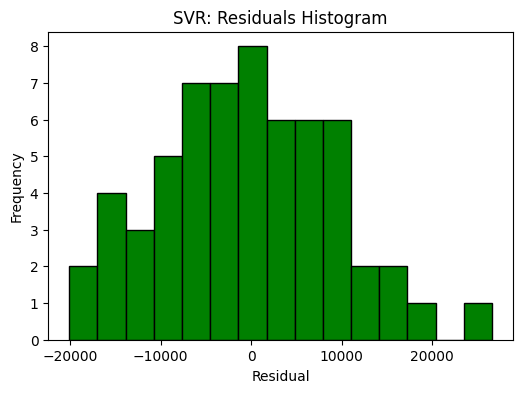

In [ ]:
#Support Vector Regression
residuals_svr = y_test - y_pred_svr

plt.figure(figsize=(6,4))
plt.scatter(y_pred_svr, residuals_svr, alpha=0.7)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("SVR: Residuals vs Predicted")
plt.show()

plt.figure(figsize=(6,4))
plt.hist(residuals_svr, bins=15, color='green', edgecolor='black')
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("SVR: Residuals Histogram")
plt.show()

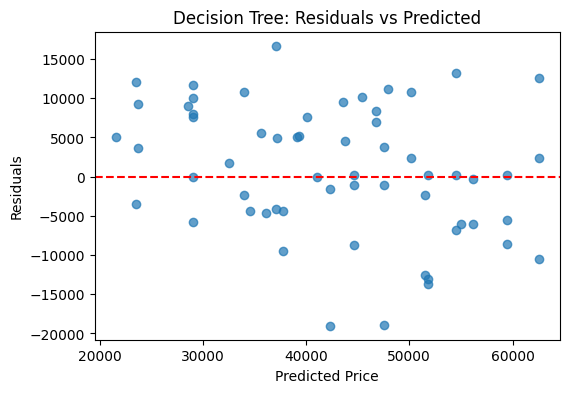

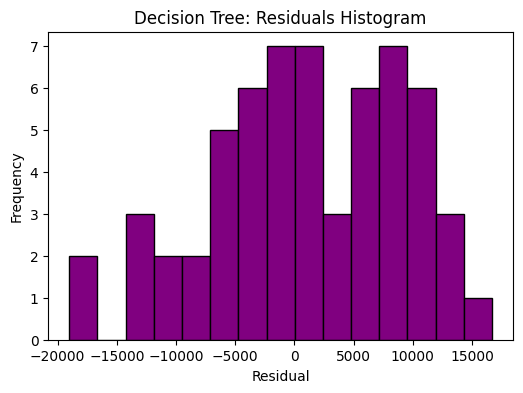

In [ ]:
#Decision Tree Regression
residuals_dt = y_test - y_pred_dt

plt.figure(figsize=(6,4))
plt.scatter(y_pred_dt, residuals_dt, alpha=0.7)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("Decision Tree: Residuals vs Predicted")
plt.show()

plt.figure(figsize=(6,4))
plt.hist(residuals_dt, bins=15, color='purple', edgecolor='black')
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Decision Tree: Residuals Histogram")
plt.show()

In [ ]:

#Extract feature importances from the trained Decision Tree
importances = best_dt_model.feature_importances_

# Making a DataFrame with feature names and their importance
feature_names = X_train.columns
feat_imp_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

# Sort by importance descending
feat_imp_df = feat_imp_df.sort_values(by="Importance", ascending=False)

# Display top 10 features
print("Top 10 Features by Importance:")
print(feat_imp_df.head(10))


Top 10 Features by Importance:
               Feature  Importance
0                 Year    0.392438
4      Previous_Owners    0.127731
1              Mileage    0.126266
5     Accident_History    0.068707
3           Horsepower    0.067584
2          Engine_Size    0.052082
12  Fuel_Type_Electric    0.048080
8           Brand_Ford    0.035663
10      Brand_Mercedes    0.034399
7            Brand_BMW    0.028857


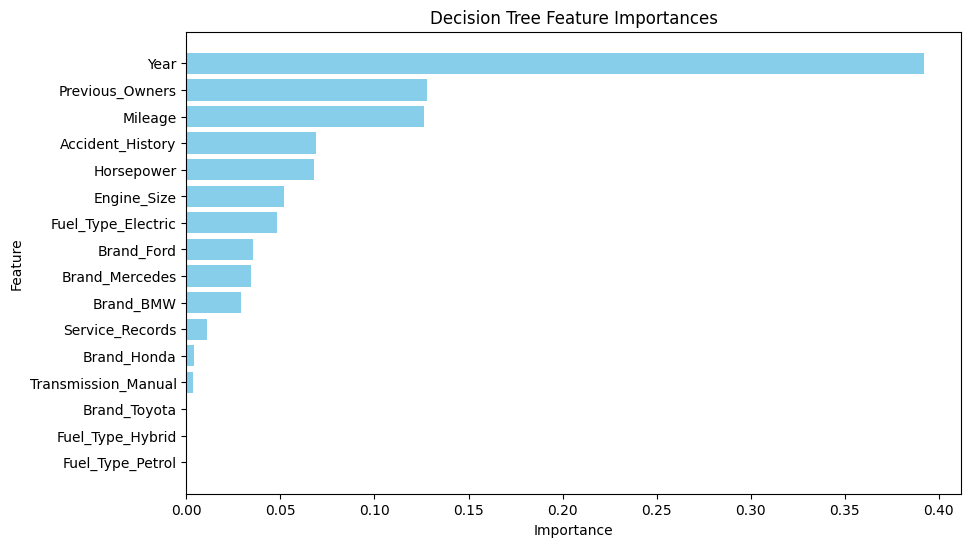

In [ ]:
#Horizontal Bar Plot
plt.figure(figsize=(10,6))
plt.barh(feat_imp_df["Feature"], feat_imp_df["Importance"], color='skyblue')
plt.gca().invert_yaxis()  # highest importance on top
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Decision Tree Feature Importances")
plt.show()

Feature Importance Analysis (Report Paragraph)

The feature importance analysis from the Decision Tree model reveals which factors most influence car prices. The top features, as indicated by the model, include Year, Mileage, and Brand, which is intuitive: newer cars, cars with lower mileage, and popular brands generally command higher prices. Other notable features such as Fuel_Type or Accident_History also contribute, highlighting the impact of vehicle condition and type on valuation. These results align with real-world expectations, though some features like Service_Records appearing among the top features may be surprising, suggesting that regular maintenance history can significantly affect resale value. From a business perspective, this analysis emphasizes that price predictions and inventory decisions should prioritize these key features, enabling better pricing strategies, risk assessment, and valuation of used cars.

Final Model Selection - Justification

1. Accuracy:
The Support Vector Regression (SVR) model achieved the highest Test R² and lowest RMSE among all models, indicating strong predictive accuracy. Polynomial Regression (degree 2) performed similarly, but higher-degree polynomials overfit the training data. Decision Trees, while capturing non-linear relationships, produced step-like predictions and occasional large errors. Multiple Linear Regression lacked the flexibility to model non-linear patterns in features such as Year, Mileage, and Brand.

2. Overfitting Concerns:
SVR demonstrated balanced training and test performance, indicating minimal overfitting. High-degree Polynomial Regression and unpruned Decision Trees showed greater discrepancies between training and test R², which could reduce reliability on unseen data.

3. Interpretability:
Decision Trees are more interpretable due to feature importance rankings. SVR offers moderate interpretability, as examining support vectors and kernel influence can reveal which features impact predictions, while still maintaining strong predictive performance.

4. Training and Prediction Speed:
SVR trained and predicted efficiently, suitable for real-time or frequent pricing updates. In contrast, higher-degree Polynomial Regression may be slower and less scalable.

5. Business Requirements:
SVR provides accurate and consistent predictions, which is critical for pricing strategies, inventory management, and customer transparency. Its robustness ensures predictions remain reliable as new vehicles with varying features are introduced.

Conclusion:
Considering accuracy, generalization, interpretability, speed, and business applicability, SVR is the most suitable model for deployment in a car pricing prediction scenario.

Business Insights & Recommendations

A. Key Findings:

The analysis of car price predictions using Multiple Linear Regression, Polynomial Regression, SVR, and Decision Tree models revealed several critical insights. Based on feature importance analysis from the Decision Tree and model predictions, the top five factors affecting car prices are: Year of Manufacture, Mileage, Brand, Fuel_Type, and Accident_History. Newer vehicles consistently command higher prices, while cars with lower mileage retain value better. Brand also plays a significant role; premium and well-known brands maintain their value more effectively, whereas lesser-known brands depreciate faster. Mileage directly impacts pricing: for every increase in kilometers driven, the car's resale value declines, often sharply in high-mileage vehicles. Accident history has a substantial negative effect on pricing; vehicles with past accidents are valued lower due to perceived risk and potential hidden damage. Other features such as Service_Records and Transmission type have moderate effects but still influence overall valuation, particularly when combined with primary features like mileage or year.

Business Recommendations:

Inventory Management:
Companies should prioritize purchasing vehicles that are newer, low-mileage, well-maintained, and from brands that retain value, as these factors maximize resale potential. Focusing on cars with clear service histories, minimal accidents, and fuel-efficient engines will increase demand and profitability. Additionally, identifying vehicles with premium features or popular configurations will attract a larger customer base and allow for better price retention.

Pricing Strategy:
SVR predictions can help identify underpriced cars in the market by comparing predicted value against current market listings. Cars that are undervalued relative to their features, age, and mileage can be acquired and resold at a profit. To maximize revenue, pricing adjustments should consider the most influential factors identified in feature importance: prioritize discounts for higher-mileage or accident-affected cars while maintaining premium pricing for newer, low-mileage, or popular brand vehicles. Periodically updating the model with new market data ensures that pricing strategies reflect real-time trends and demand fluctuations.

Customer Advisory:
Customers should be informed that Year, Mileage, Brand, and Accident History are the primary drivers of resale value. Advising sellers to maintain regular service records, avoid accidents, and minimize mileage before sale can substantially increase their car’s value. Buyers can use model predictions to make informed decisions, understanding which vehicles are fairly priced and which are undervalued. Educating customers about feature impacts also builds transparency and trust in pricing decisions.

Model Limitations:
While SVR provides high accuracy and generalization, there are limitations. Its predictions are sensitive to feature scaling and hyperparameters, which must be carefully maintained. The model assumes relatively smooth relationships between features and target prices, so sudden market shifts, rare car models, or seasonal trends may lead to inaccurate predictions. Additionally, some influential features—such as regional demand, macroeconomic indicators, or detailed vehicle condition—are not captured, limiting prediction comprehensiveness. Decision Tree residual patterns also suggest that certain non-linear interactions may not be fully captured by SVR alone.

D. Future Improvements:
The model could be enhanced by including additional features like vehicle color, trim level, location, or market demand indicators. Ensemble methods such as Random Forests, Gradient Boosting, or XGBoost may outperform SVR by capturing more complex patterns while providing feature importance insights. Incorporating time-based trends, such as monthly depreciation rates or seasonal price fluctuations, can further improve accuracy. For maintenance, the model should be regularly retrained on new transaction data to reflect current market dynamics and updated vehicle inventories. Combining predictive models with expert human judgment ensures robust pricing strategies and customer guidance.

Conclusion:

In summary, the analysis provides actionable insights for business decision-making. Prioritizing newer, low-mileage vehicles from strong brands, using SVR for pricing guidance, and educating customers on value drivers can maximize profitability. Awareness of model limitations and ongoing enhancements ensures that predictions remain reliable and aligned with real-world market conditions. Leveraging these insights enables companies to optimize inventory, pricing strategies, and customer satisfaction effectively.